# 08 — NIH-NLM zero-shot і адаптація без міток (EXPLORATORY)

Ноутбук лише читає `reports/tables/nih_zeroshot_*.csv` і `adapt_*.csv`. Деталі: `reports/nih_zeroshot_summary.md`,
`reports/adapt_bbbc_test_summary.md`.

**Адаптація на NIH не завершена:** таблиць `adapt_nih_*` поки немає, нижче лише BBBC041 test.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from malaria_ssl.detr.compare import plot_paired_diffs
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
F = resolve_path('reports/figures')


def ci(v, lo, hi):
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'


def wide(df, index, columns, v='value', lo='ci_low', hi='ci_high'):
    """Long table of value + CI -> formatted pivot."""
    d = df.assign(s=[ci(a, b, c) for a, b, c in zip(df[v], df[lo], df[hi])])
    return d.pivot(index=index, columns=columns, values='s')


## NIH: усі метрики, середнє 3 seed боксів A

965 зображень, 193 пацієнти; ДІ — bootstrap по пацієнтах; пороги з BBBC041 val.

In [2]:
n = pd.read_csv(T / 'nih_zeroshot_runs.csv')
a = n[(n['subset'] == 'all') & (n['run'] == 'a_3s')]
wide(a[a['metric'].isin(['AP50', 'precision', 'recall', 'f1'])], 'method', 'metric')[['AP50', 'precision', 'recall', 'f1']]

metric,AP50,precision,recall,f1
method,,,,
agnostic,"0.978 [0.978, 0.981]","0.991 [0.990, 0.993]","0.969 [0.962, 0.974]","0.980 [0.976, 0.983]"
e2e,"0.072 [0.052, 0.096]","0.545 [0.454, 0.627]","0.030 [0.021, 0.040]","0.056 [0.041, 0.075]"
ref_dino,"0.423 [0.359, 0.484]","0.804 [0.741, 0.849]","0.112 [0.089, 0.137]","0.196 [0.159, 0.236]"
ref_imagenet,"0.451 [0.391, 0.507]","0.805 [0.747, 0.856]","0.095 [0.073, 0.119]","0.170 [0.133, 0.208]"
ssl_v2_b,"0.557 [0.502, 0.608]","0.908 [0.868, 0.935]","0.112 [0.090, 0.139]","0.199 [0.164, 0.241]"
ssl_v2_b_seed43,"0.579 [0.525, 0.626]","0.911 [0.870, 0.938]","0.081 [0.063, 0.103]","0.149 [0.117, 0.186]"
ssl_v2_cont,"0.510 [0.460, 0.556]","0.933 [0.898, 0.960]","0.064 [0.048, 0.084]","0.120 [0.092, 0.154]"
ssl_v2_cont_seed43,"0.525 [0.467, 0.576]","0.900 [0.852, 0.935]","0.071 [0.056, 0.090]","0.132 [0.105, 0.164]"


## Локалізація переноситься, класифікація ні

AP50 infected на BBBC041 test і NIH для тих самих моделей.

,BBBC041 test,NIH
end_to_end,0.550,0.072
ref_dino,0.680,0.423
ssl_v2_cont,0.711,0.510
ssl_v2_cont_seed43,0.691,0.525
ssl_v2_b,0.751,0.557
ssl_v2_b_seed43,0.773,0.579


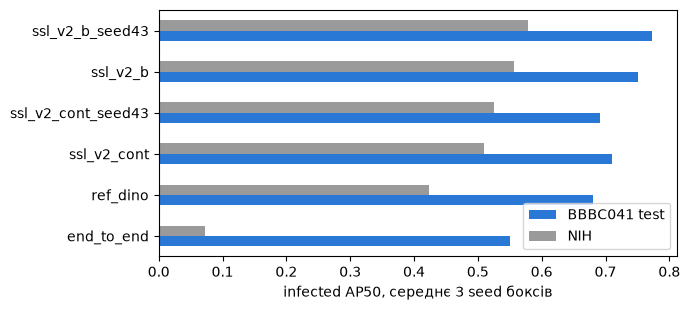

In [3]:
s = pd.read_csv(T / 'phase7_two_stage_seed2.csv')
s = s[(s['run'] == 'a_3s') & (s['split'] == 'test') & s['training'].isin(['clean', '-'])].set_index('encoder')['AP50']
nih = a[a['metric'] == 'AP50'].set_index('method')['value'].rename({'e2e': 'end_to_end'})
c = pd.DataFrame({'BBBC041 test': s, 'NIH': nih}).dropna().sort_values('NIH')
ax = c.plot.barh(figsize=(7, 3.2), color=['#2a78d6', '#9a9a9a'])
ax.set_xlabel('infected AP50, середнє 3 seed боксів')
plt.tight_layout()
c.round(3)

## Парні різниці на NIH (bootstrap по пацієнтах)

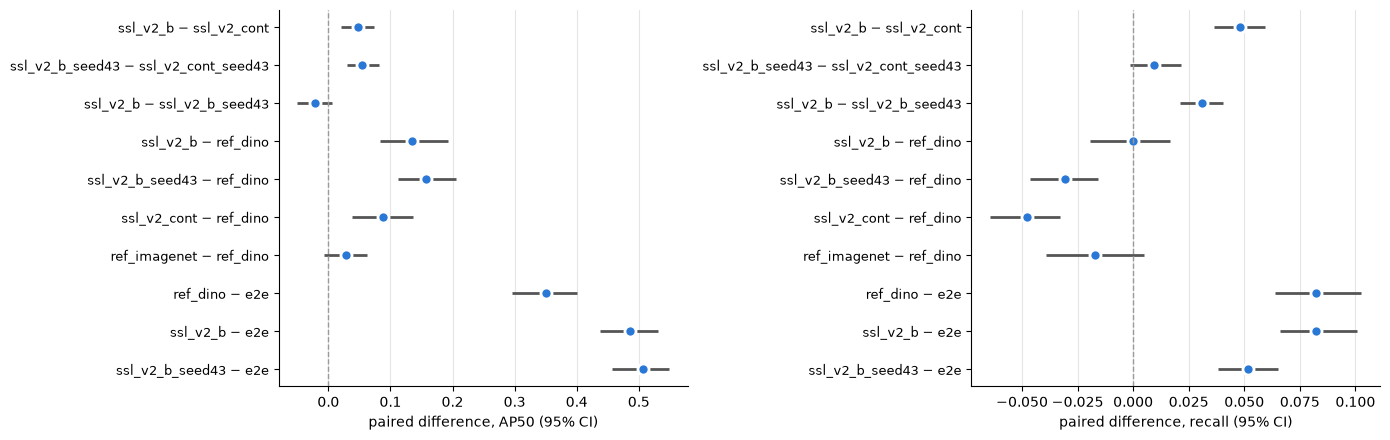

In [4]:
d = pd.read_csv(T / 'nih_zeroshot_diff.csv')
d = d[(d['subset'] == 'all') & (d['run'] == 'a_3s')].copy()
d[['a', 'b']] = d['pair'].str.split(' - ', expand=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_paired_diffs(d, 'AP50', axes[0])
plot_paired_diffs(d, 'recall', axes[1])
plt.tight_layout()

## Адаптація без міток: BBBC041 test

Гіперпараметри зафіксовано на stain-shifted val. Таблиця не є вибором методу за test.

In [5]:
r = pd.read_csv(T / 'adapt_bbbc_test_runs.csv')
m = r[r['run'] == 'a_3s']
m[m['metric'] == 'AP50'].pivot(index='method', columns='encoder', values='value').round(3)

encoder,ref_dino,ref_imagenet,ssl_v2_b,ssl_v2_b_seed43,ssl_v2_cont,ssl_v2_cont_seed43
method,,,,,,
adabn,0.675,0.599,0.628,0.685,0.621,0.628
adabn+bbse,0.699,0.642,0.699,0.723,0.680,0.672
adabn+em,0.701,0.642,0.700,0.726,0.687,0.673
cbr,0.666,0.562,0.659,0.683,0.609,0.639
cbr+bbse,0.702,0.625,0.721,0.729,0.674,0.680
cbr+em,0.703,0.631,0.723,0.732,0.682,0.681
coral,0.670,0.606,0.702,0.736,0.672,0.647
coral+bbse,0.674,0.598,0.718,0.749,0.700,0.669
coral+em,0.672,0.595,0.720,0.748,0.700,0.673


In [6]:
m[m['metric'] == 'recall'].pivot(index='method', columns='encoder', values='value').round(3)

encoder,ref_dino,ref_imagenet,ssl_v2_b,ssl_v2_b_seed43,ssl_v2_cont,ssl_v2_cont_seed43
method,,,,,,
adabn,0.617,0.502,0.692,0.700,0.656,0.729
adabn+bbse,0.704,0.657,0.866,0.845,0.822,0.831
adabn+em,0.606,0.537,0.792,0.757,0.739,0.767
cbr,0.678,0.554,0.663,0.707,0.671,0.702
cbr+bbse,0.805,0.746,0.862,0.878,0.855,0.837
cbr+em,0.716,0.646,0.780,0.782,0.779,0.768
coral,0.443,0.328,0.491,0.449,0.414,0.487
coral+bbse,0.566,0.493,0.648,0.668,0.593,0.616
coral+em,0.464,0.315,0.482,0.469,0.421,0.484


## Парні різниці метод − none, енкодер `ssl_v2_b_seed43`

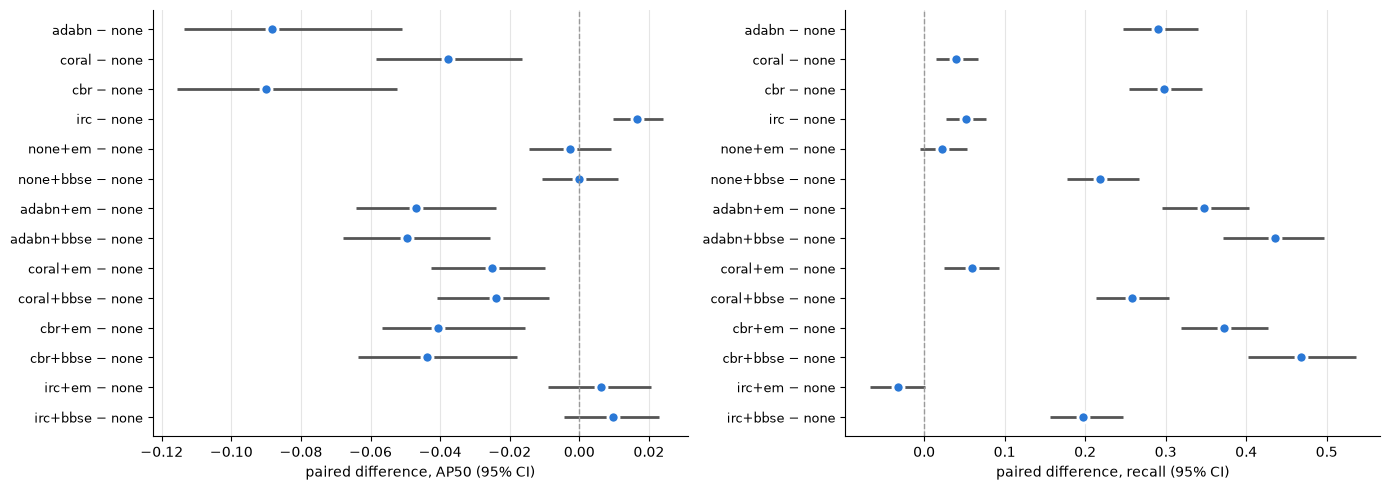

In [7]:
p = pd.read_csv(T / 'adapt_bbbc_test_diff.csv')
p = p[(p['run'] == 'a_3s') & (p['encoder'] == 'ssl_v2_b_seed43') & (p['pair'] != 'none_stainthr - none')].copy()
p[['a', 'b']] = p['pair'].str.split(' - ', expand=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_paired_diffs(p, 'AP50', axes[0])
plot_paired_diffs(p, 'recall', axes[1])
plt.tight_layout()